In [ ]:
from google.colab import files
files.upload()   # choose student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [ ]:
import pandas as pd, numpy as np, json, joblib
df = pd.read_csv("student-mat.csv", sep=";")
df["at_risk"] = (df["G3"] < 10).astype(int)   # 1 = final grade below 10/20

NUM = ["age","Medu","Fedu","studytime","failures","goout","health","absences","G1"]
CAT = ["sex","address","schoolsup","famsup","higher","internet"]
FEATURES = NUM + CAT

print(df.shape)
print(df["at_risk"].value_counts())
print("missing values:", df[FEATURES].isnull().sum().sum())

(395, 34)
at_risk
0    265
1    130
Name: count, dtype: int64
missing values: 0


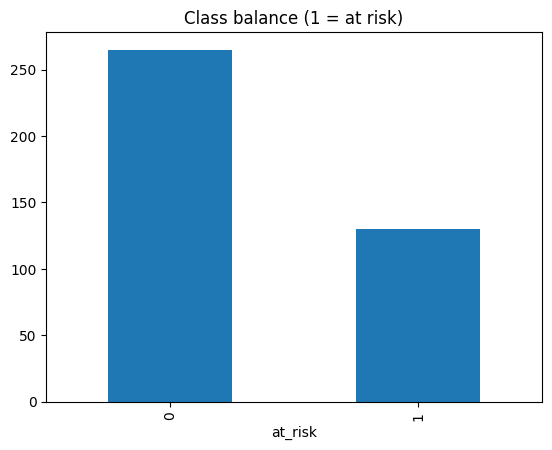

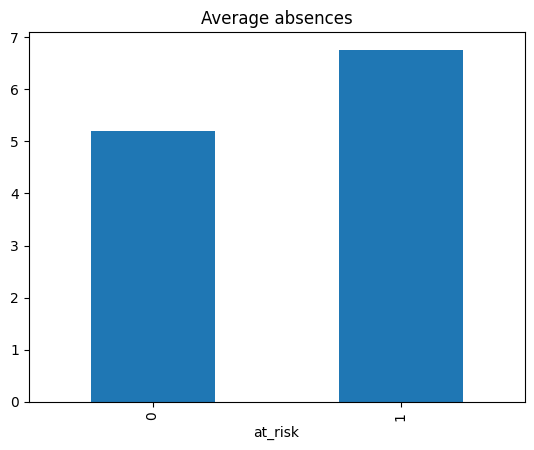

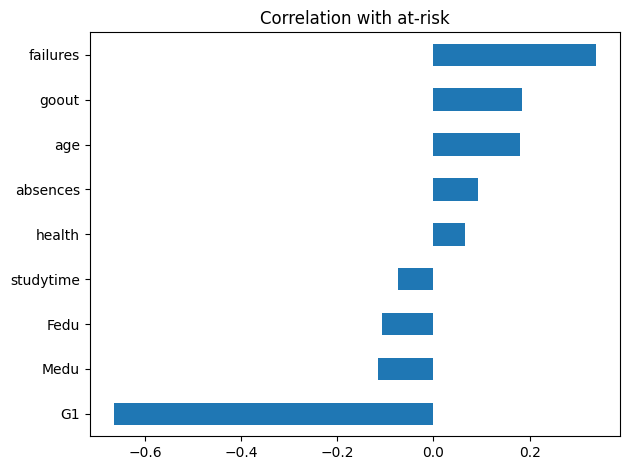

In [ ]:
import matplotlib.pyplot as plt
df["at_risk"].value_counts().plot(kind="bar", title="Class balance (1 = at risk)")
plt.savefig("class_balance.png"); plt.show()

df.groupby("at_risk")["absences"].mean().plot(kind="bar", title="Average absences")
plt.show()

df[NUM + ["at_risk"]].corr()["at_risk"].drop("at_risk").sort_values().plot(
    kind="barh", title="Correlation with at-risk")
plt.tight_layout(); plt.savefig("correlation.png"); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

X, y = df[FEATURES], df["at_risk"]
pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
Xtr = pre.fit_transform(X_train).astype("float32")
Xte = pre.transform(X_test).astype("float32")
print(Xtr.shape, Xte.shape)

(316, 21) (79, 21)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
base = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
print(classification_report(y_test, base.predict(Xte)))

              precision    recall  f1-score   support

           0       0.86      0.92      0.89        53
           1       0.82      0.69      0.75        26

    accuracy                           0.85        79
   macro avg       0.84      0.81      0.82        79
weighted avg       0.85      0.85      0.84        79



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(Xtr.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.Recall(name="recall")])

neg, pos = np.bincount(y_train)
history = model.fit(
    Xtr, y_train, validation_split=0.2, epochs=200, batch_size=16,
    class_weight={0: 1.0, 1: neg / pos},
    callbacks=[EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
    verbose=2)

Epoch 1/200
16/16 - 2s - 105ms/step - accuracy: 0.5952 - loss: 0.9497 - recall: 0.4886 - val_accuracy: 0.6406 - val_loss: 0.6619 - val_recall: 0.8750
Epoch 2/200
16/16 - 0s - 8ms/step - accuracy: 0.6310 - loss: 0.8394 - recall: 0.6477 - val_accuracy: 0.6094 - val_loss: 0.6421 - val_recall: 0.8750
Epoch 3/200
16/16 - 0s - 8ms/step - accuracy: 0.6468 - loss: 0.7954 - recall: 0.6932 - val_accuracy: 0.6406 - val_loss: 0.5888 - val_recall: 0.8125
Epoch 4/200
16/16 - 0s - 8ms/step - accuracy: 0.7302 - loss: 0.7355 - recall: 0.7273 - val_accuracy: 0.6562 - val_loss: 0.5463 - val_recall: 0.8125
Epoch 5/200
16/16 - 0s - 8ms/step - accuracy: 0.7183 - loss: 0.7142 - recall: 0.7500 - val_accuracy: 0.6875 - val_loss: 0.5411 - val_recall: 0.8750
Epoch 6/200
16/16 - 0s - 9ms/step - accuracy: 0.7540 - loss: 0.6717 - recall: 0.8068 - val_accuracy: 0.7188 - val_loss: 0.5171 - val_recall: 0.8750
Epoch 7/200
16/16 - 0s - 8ms/step - accuracy: 0.7817 - loss: 0.6016 - recall: 0.8295 - val_accuracy: 0.7344 - 

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
              precision    recall  f1-score   support

           0       0.91      0.81      0.86        53
           1       0.69      0.85      0.76        26

    accuracy                           0.82        79
   macro avg       0.80      0.83      0.81        79
weighted avg       0.84      0.82      0.83        79

[[43 10]
 [ 4 22]]


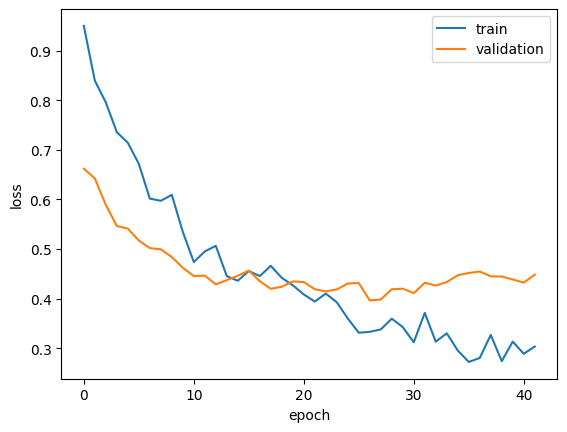

In [ ]:
pred = (model.predict(Xte) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.savefig("loss_curve.png"); plt.show()

In [ ]:
model.save("risk_model.keras")
joblib.dump(pre, "preprocessor.joblib")
json.dump(FEATURES, open("feature_columns.json", "w"))

import sklearn
print("TF", tf.__version__, "| sklearn", sklearn.__version__)

from google.colab import files
for f in ["risk_model.keras", "preprocessor.joblib", "feature_columns.json"]:
    files.download(f)

TF 2.21.0 | sklearn 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   ## Experiment 2: higher-education dataset

In [11]:
import pandas as pd, numpy as np

url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
try:
    df2 = pd.read_csv(url, sep=";")
except Exception as e:
    print("Direct download failed:", e)
    from google.colab import files
    files.upload()   # upload data.csv from the unzipped folder
    df2 = pd.read_csv("data.csv", sep=";")

df2.columns = df2.columns.str.strip()
print(df2.shape)
print(df2["Target"].value_counts())

(4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [12]:
df2["at_risk"] = (df2["Target"] == "Dropout").astype(int)   # 1 = dropped out

USE_FIRST_SEM = True   # set False for a prediction using enrollment information only
early_cols = [c for c in df2.columns
              if c not in ("Target", "at_risk")
              and "2nd sem" not in c
              and (USE_FIRST_SEM or "1st sem" not in c)]

print(len(early_cols), "features")
print(df2["at_risk"].value_counts(normalize=True))

30 features
at_risk
0    0.678797
1    0.321203
Name: proportion, dtype: float64


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# These columns are numeric codes for categories (course, occupation...), not quantities
CODE_COLS = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]
cat2 = [c for c in CODE_COLS if c in early_cols]
num2 = [c for c in early_cols if c not in cat2]
print("categorical:", cat2)

X2, y2 = df2[early_cols], df2["at_risk"]
pre2 = ColumnTransformer([
    ("num", StandardScaler(), num2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat2),
])

Xtr_a, Xte_a, ytr, yte = train_test_split(X2, y2, test_size=0.2, stratify=y2, random_state=42)
Xtr2 = pre2.fit_transform(Xtr_a).astype("float32")
Xte2 = pre2.transform(Xte_a).astype("float32")
print(Xtr2.shape, Xte2.shape)

categorical: ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
(3539, 229) (885, 229)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
tf.random.set_seed(42)

base2 = LogisticRegression(max_iter=2000).fit(Xtr2, ytr)
print("Logistic regression")
print(classification_report(yte, base2.predict(Xte2)))

model2 = models.Sequential([
    layers.Input(shape=(Xtr2.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
])
model2.compile(optimizer="adam", loss="binary_crossentropy",
               metrics=["accuracy", tf.keras.metrics.Recall(name="recall")])

neg, pos = np.bincount(ytr)
hist2 = model2.fit(Xtr2, ytr, validation_split=0.2, epochs=200, batch_size=32,
                   class_weight={0: 1.0, 1: neg / pos},
                   callbacks=[EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
                   verbose=0)

pred2 = (model2.predict(Xte2) > 0.5).astype(int).ravel()
print("ANN")
print(classification_report(yte, pred2))
print(confusion_matrix(yte, pred2))

Logistic regression
              precision    recall  f1-score   support

           0       0.87      0.94      0.91       601
           1       0.85      0.70      0.77       284

    accuracy                           0.87       885
   macro avg       0.86      0.82      0.84       885
weighted avg       0.86      0.87      0.86       885

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
ANN
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       601
           1       0.79      0.74      0.76       284

    accuracy                           0.85       885
   macro avg       0.83      0.82      0.83       885
weighted avg       0.85      0.85      0.85       885

[[545  56]
 [ 74 210]]


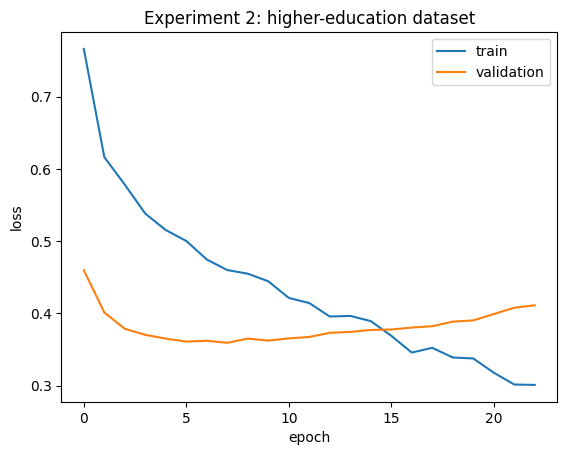

In [15]:
import matplotlib.pyplot as plt
plt.plot(hist2.history["loss"], label="train")
plt.plot(hist2.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
plt.title("Experiment 2: higher-education dataset")
plt.savefig("loss_curve_exp2.png"); plt.show()